
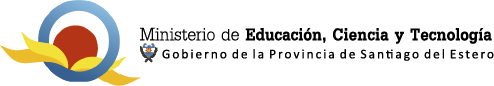

# Clase 6: Deep Learning con Keras. TP1

## Materia: Sistemas de Inteligencia Artificial

## Contenidos:

* Redes Neuronales Convolucionales con Keras




En este laboratorio, aprenderemos a utilizar la biblioteca Keras para construir redes neuronales convolucionales. También utilizaremos el popular conjunto de datos MNIST y compararemos nuestros resultados con los obtenidos mediante una red neuronal convencional.


## Objetivos para este Notebook
* Cómo utilizar la biblioteca Keras para construir redes neuronales convolucionales
* Red neuronal convolucional con un conjunto de capas de convolución y agrupamiento
* Red neuronal convolucional con dos conjuntos de capas convolucionales y de agrupamiento



## Tabla de Contenidos

<div class="alert alert-block alert-info" style="margin-top: 20px">

<font size = 3>
      
1. <a href="#Importar-Keras-y-Paquetes">Importar Keras y Paquetes</a>
2. <a href="#Red-Neuronal-Convolucional-con-Un-Conjunto-de-Capas-Convolucionales-y-Capas-de-Pooling">Red Neuronal Convolucional con Un Conjunto de Capas Convolucionales y Capas de Pooling</a>
3. <a href="#Red-Neuronal-Convolucional-con-Dos-Conjuntos-de-Capas-Convolucionales-y-Pooling">Red Neuronal Convolucional con Dos Conjuntos de Capas Convolucionales y Pooling</a>  

</fuente>
</div>


### Instala las bibliotecas necesarias


Comencemos instalando las bibliotecas de keras y los paquetes que necesitaremos para construir una red neuronal.


In [1]:
#Todas las bibliotecas necesarias para este laboratorio se enumeran a continuación. Las bibliotecas deben instalarse en Skills Network Labs.
#Si ejecutas este cuaderno en un entorno diferente, por ejemplo, en tu computadora de escritorio, es posible que quieras instalarlas.
#!pip install numpy==2.0.2
#!pip install pandas==2.2.2
#!pip install tensorflow_cpu==2.18.0
#!pip install matplotlib==3.9.2

#### Suprimir los mensajes de advertencia de tensorflow
Utilizamos el siguiente código para suprimir los mensajes de advertencia debido al uso de la arquitectura de CPU para TensorFlow.
Es posible que desees **comentar estas líneas** si estás utilizando la arquitectura GPU.


## Importar Keras y Paquetes


In [2]:
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Input
from keras.utils import to_categorical

Cuando trabajamos con redes neuronales convolucionales en particular, necesitaremos paquetes adicionales.


In [3]:
from keras.layers import Conv2D # para adicionar capas convolucionales
from keras.layers import MaxPooling2D # para adicionar capas de pooling
from keras.layers import Flatten # para aplanar los datos para las capas fully connected

## Red Neuronal Convolucional con un Conjunto de Capas Convolucionales y de Agrupamiento


In [4]:
# importamos datos
from keras.datasets import mnist

# cargamos datos
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# reformamos para que tenga [samples][canales][width][height]
X_train = X_train.reshape(X_train.shape[0], 28, 28, 1).astype('float32')
X_test = X_test.reshape(X_test.shape[0], 28, 28, 1).astype('float32')
print(y_test[0])
print(X_train.shape)
print(X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
7
(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [5]:
X_test.shape

(10000, 28, 28, 1)

In [6]:
X_train[0]

array([[[  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.]],

       [[  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.]],

       [[  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
    

Normalicemos los valores de los píxeles para que estén entre 0 y 1.


In [7]:
X_train = X_train / 255 # normalizamos los datos de training
X_test = X_test / 255 # normalizamos los datos de test

A continuación, convirtamos la variable objetivo en categorías binarias.


In [8]:
print(y_test[9])
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

print(y_test[9])
num_classes = y_test.shape[1] # numero de categorias

9
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


A continuación, definamos una función que cree nuestro modelo. Comencemos con un conjunto de capas de convolución y agrupamiento.


In [9]:
def convolutional_model():

    # creamos el modelo
    model = Sequential()
    model.add(Input(shape=(28, 28, 1)))#28x28
    model.add(Conv2D(16, (5, 5), strides=(1, 1), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))#14x14

    model.add(Flatten())#196
    model.add(Dense(100, activation='relu'))#100
    model.add(Dense(num_classes, activation='softmax'))#10

    # compilar el modelo
    model.compile(optimizer='adam', loss='categorical_crossentropy',  metrics=['accuracy'])
    return model

Finalmente, llamemos a la función para crear el modelo, y luego lo entrenemos y evaluemos.


In [10]:
# construimos el modelo
model = convolutional_model()

# ajustamos o entrenamos el modelo y guardamos el historial para graficar
history_1set = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=200, verbose=2)

# evaluamos el modelo
scores = model.evaluate(X_test, y_test, verbose=0)
print("Accuracy: {} \n Error: {}".format(scores[1], 100-scores[1]*100))

Epoch 1/10
300/300 - 24s - 82ms/step - accuracy: 0.9216 - loss: 0.2846 - val_accuracy: 0.9716 - val_loss: 0.0972
Epoch 2/10
300/300 - 23s - 76ms/step - accuracy: 0.9759 - loss: 0.0814 - val_accuracy: 0.9803 - val_loss: 0.0618
Epoch 3/10
300/300 - 23s - 75ms/step - accuracy: 0.9825 - loss: 0.0581 - val_accuracy: 0.9830 - val_loss: 0.0516
Epoch 4/10
300/300 - 42s - 141ms/step - accuracy: 0.9867 - loss: 0.0444 - val_accuracy: 0.9854 - val_loss: 0.0449
Epoch 5/10
300/300 - 22s - 74ms/step - accuracy: 0.9890 - loss: 0.0357 - val_accuracy: 0.9851 - val_loss: 0.0443
Epoch 6/10
300/300 - 21s - 70ms/step - accuracy: 0.9915 - loss: 0.0286 - val_accuracy: 0.9855 - val_loss: 0.0425
Epoch 7/10
300/300 - 43s - 142ms/step - accuracy: 0.9925 - loss: 0.0247 - val_accuracy: 0.9858 - val_loss: 0.0371
Epoch 8/10
300/300 - 41s - 135ms/step - accuracy: 0.9941 - loss: 0.0202 - val_accuracy: 0.9881 - val_loss: 0.0375
Epoch 9/10
300/300 - 41s - 136ms/step - accuracy: 0.9952 - loss: 0.0166 - val_accuracy: 0.988

------------------------------------------


## Red Neuronal Convolucional con Dos Conjuntos de Capas Convolucionales y de Agrupamiento


Redefinamos nuestro modelo convolucional para que tenga dos capas de convolución y agrupamiento en lugar de solo una capa de cada tipo.


In [11]:
def convolutional_model():

    # creamos el modelo
    model = Sequential()
    model.add(Input(shape=(28, 28, 1)))
    model.add(Conv2D(16, (5, 5), activation='relu'))#16 mapas de características
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))#14x14

    model.add(Conv2D(8, (2, 2), activation='relu'))#8 mapas de características
    model.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2))) #7x7

    model.add(Flatten())
    model.add(Dense(100, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))

    # compilamos el modelo
    model.compile(optimizer='adam', loss='categorical_crossentropy',  metrics=['accuracy'])
    return model

Ahora, llamemos a la función para crear nuestra nueva red neuronal convolucional, y luego la entrenaremos y evaluaremos.


In [12]:
# construimos el modelo
model = convolutional_model()

# ajustamos o entrenamos el modelo y guardamos el historial para graficar
history_2set = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=200, verbose=2)

# evaluamos el modelo
scores = model.evaluate(X_test, y_test, verbose=0)
print("Accuracy: {} \n Error: {}".format(scores[1], 100-scores[1]*100))

Epoch 1/10
300/300 - 24s - 82ms/step - accuracy: 0.8688 - loss: 0.4733 - val_accuracy: 0.9626 - val_loss: 0.1207
Epoch 2/10
300/300 - 24s - 80ms/step - accuracy: 0.9681 - loss: 0.1069 - val_accuracy: 0.9756 - val_loss: 0.0762
Epoch 3/10
300/300 - 24s - 79ms/step - accuracy: 0.9766 - loss: 0.0759 - val_accuracy: 0.9783 - val_loss: 0.0662
Epoch 4/10
300/300 - 22s - 74ms/step - accuracy: 0.9801 - loss: 0.0633 - val_accuracy: 0.9821 - val_loss: 0.0533
Epoch 5/10
300/300 - 42s - 141ms/step - accuracy: 0.9836 - loss: 0.0521 - val_accuracy: 0.9859 - val_loss: 0.0436
Epoch 6/10
300/300 - 41s - 136ms/step - accuracy: 0.9858 - loss: 0.0461 - val_accuracy: 0.9875 - val_loss: 0.0414
Epoch 7/10
300/300 - 25s - 82ms/step - accuracy: 0.9873 - loss: 0.0408 - val_accuracy: 0.9872 - val_loss: 0.0395
Epoch 8/10
300/300 - 22s - 73ms/step - accuracy: 0.9889 - loss: 0.0367 - val_accuracy: 0.9874 - val_loss: 0.0414
Epoch 9/10
300/300 - 23s - 78ms/step - accuracy: 0.9894 - loss: 0.0335 - val_accuracy: 0.9886 

Haz un gráfico que muestre la pérdida y la exactitud a medida que se entrena el modelo. Comenta, qué observas?

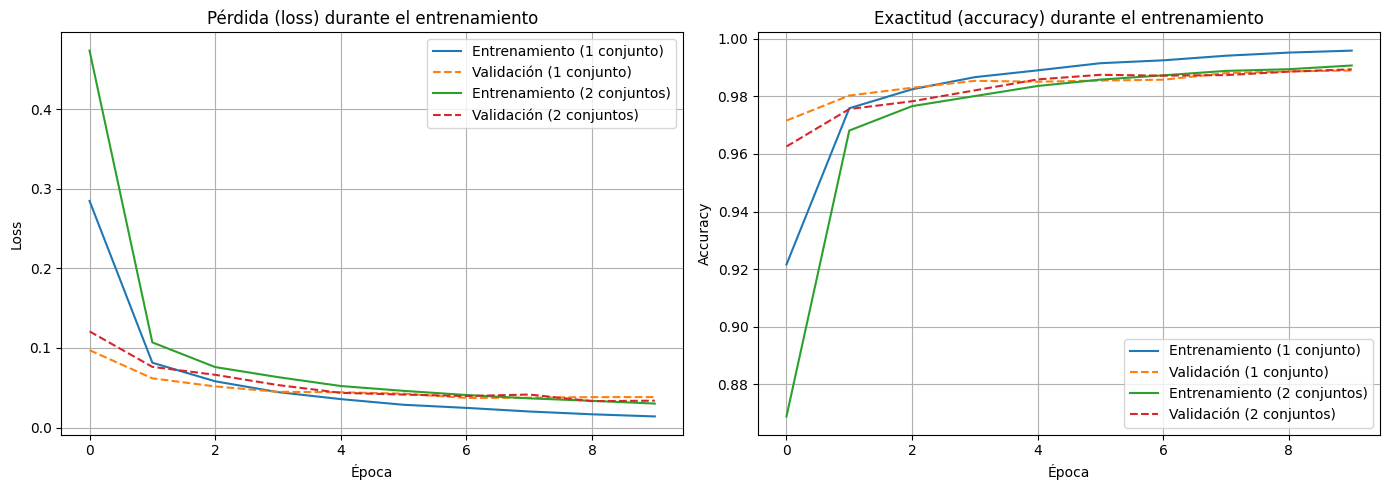

In [13]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# pérdida (loss)
ax1.plot(history_1set.history['loss'], label='Entrenamiento (1 conjunto)')
ax1.plot(history_1set.history['val_loss'], label='Validación (1 conjunto)', linestyle='--')
ax1.plot(history_2set.history['loss'], label='Entrenamiento (2 conjuntos)')
ax1.plot(history_2set.history['val_loss'], label='Validación (2 conjuntos)', linestyle='--')
ax1.set_title('Pérdida (loss) durante el entrenamiento')
ax1.set_xlabel('Época')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# exactitud (accuracy)
ax2.plot(history_1set.history['accuracy'], label='Entrenamiento (1 conjunto)')
ax2.plot(history_1set.history['val_accuracy'], label='Validación (1 conjunto)', linestyle='--')
ax2.plot(history_2set.history['accuracy'], label='Entrenamiento (2 conjuntos)')
ax2.plot(history_2set.history['val_accuracy'], label='Validación (2 conjuntos)', linestyle='--')
ax2.set_title('Exactitud (accuracy) durante el entrenamiento')
ax2.set_xlabel('Época')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

**Observación - qué observo en los gráficos:**

- La **pérdida** desciende rápidamente en las primeras épocas y luego se aplana cerca de cero, mientras que la **exactitud** crece hasta estabilizarse en valores cercanos al 98-99%.
- Las curvas de **validación** acompañan a las de **entrenamiento** con una diferencia pequeña y constante: el modelo generaliza bien y no se observa sobreajuste (overfitting) marcado.
- La red con **dos conjuntos** de capas conv+pooling extrae características más complejas y alcanza una exactitud igual o algo superior a la de un solo conjunto, aunque tarda un poco más en entrenar.
- A partir de cierta época (aprox. 5-6) las mejoras son marginales: la curva se aplana y el modelo ya convergió.

<h3>Ejercicio Práctico 1</h3>


Veamos cómo el tamaño del lote afecta el tiempo requerido y la precisión del entrenamiento del modelo.
Para esto, puedes intentar cambiar el tamaño del lote (batch_size) a 1024 y verificar su efecto en la precisión.


In [14]:
import time

# construimos el modelo desde cero (la última versión definida: dos conjuntos conv+pooling)
model = convolutional_model()

# medimos el tiempo que requiere el entrenamiento
inicio = time.time()

# entrenamos con batch_size=1024 (10 épocas)
history_batch = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=1024, verbose=2)

print("Tiempo de entrenamiento: {:.1f} segundos".format(time.time() - inicio))

# evaluamos el modelo
scores = model.evaluate(X_test, y_test, verbose=0)
print("Accuracy: {} \n Error: {}".format(scores[1], 100 - scores[1] * 100))

Epoch 1/10
59/59 - 24s - 404ms/step - accuracy: 0.6818 - loss: 1.1933 - val_accuracy: 0.8978 - val_loss: 0.3614
Epoch 2/10
59/59 - 24s - 407ms/step - accuracy: 0.9205 - loss: 0.2801 - val_accuracy: 0.9462 - val_loss: 0.1956
Epoch 3/10
59/59 - 24s - 400ms/step - accuracy: 0.9474 - loss: 0.1814 - val_accuracy: 0.9590 - val_loss: 0.1416
Epoch 4/10
59/59 - 23s - 390ms/step - accuracy: 0.9598 - loss: 0.1363 - val_accuracy: 0.9698 - val_loss: 0.1091
Epoch 5/10
59/59 - 42s - 704ms/step - accuracy: 0.9668 - loss: 0.1116 - val_accuracy: 0.9746 - val_loss: 0.0881
Epoch 6/10
59/59 - 41s - 698ms/step - accuracy: 0.9711 - loss: 0.0965 - val_accuracy: 0.9775 - val_loss: 0.0789
Epoch 7/10
59/59 - 25s - 418ms/step - accuracy: 0.9746 - loss: 0.0855 - val_accuracy: 0.9779 - val_loss: 0.0700
Epoch 8/10
59/59 - 22s - 379ms/step - accuracy: 0.9759 - loss: 0.0791 - val_accuracy: 0.9777 - val_loss: 0.0694
Epoch 9/10
59/59 - 42s - 719ms/step - accuracy: 0.9782 - loss: 0.0722 - val_accuracy: 0.9803 - val_loss:

**Observación - efecto del batch_size=1024:**

- Con lotes de 1024 cada época tiene muchas menos iteraciones (60000/1024 = 59 pasos en lugar de 300 con batch_size=200), por lo que el entrenamiento es **más rápido**.
- Los lotes más grandes dan gradientes más estables pero menos actualizaciones de pesos por época; la **precisión final** se mantiene muy similar a la del entrenamiento con batch_size=200 (en torno al 98%), con alguna pequeña variación.

<h3>Ejercicio de Práctica 2</h3>


Ahora, veamos cómo el número de épocas afecta el tiempo requerido y la precisión del entrenamiento del modelo.
Para esto, puedes mantener el batch_size=1024 y epochs=25 y verificar su efecto en la precisión.


In [ ]:
import time
import matplotlib.pyplot as plt

# construimos el modelo desde cero (la última versión definida: dos conjuntos conv+pooling)
model = convolutional_model()

# medimos el tiempo que requiere el entrenamiento
inicio = time.time()

# entrenamos con batch_size=1024 y 25 épocas
history_epochs = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=25, batch_size=1024, verbose=2)

print("Tiempo de entrenamiento: {:.1f} segundos".format(time.time() - inicio))

# evaluamos el modelo
scores = model.evaluate(X_test, y_test, verbose=0)
print("Accuracy: {} \n Error: {}".format(scores[1], 100 - scores[1] * 100))

# graficamos la exactitud a lo largo de las épocas
plt.figure(figsize=(7, 4))
plt.plot(history_epochs.history['accuracy'], label='Entrenamiento')
plt.plot(history_epochs.history['val_accuracy'], label='Validación')
plt.title('Exactitud con 25 épocas y batch_size=1024')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

Epoch 1/25
59/59 - 34s - 575ms/step - accuracy: 0.6283 - loss: 1.3144 - val_accuracy: 0.8902 - val_loss: 0.3829
Epoch 2/25
59/59 - 24s - 402ms/step - accuracy: 0.9131 - loss: 0.2938 - val_accuracy: 0.9431 - val_loss: 0.2030
Epoch 3/25
59/59 - 23s - 384ms/step - accuracy: 0.9451 - loss: 0.1891 - val_accuracy: 0.9581 - val_loss: 0.1419
Epoch 4/25
59/59 - 42s - 704ms/step - accuracy: 0.9589 - loss: 0.1402 - val_accuracy: 0.9670 - val_loss: 0.1134
Epoch 5/25
59/59 - 42s - 707ms/step - accuracy: 0.9668 - loss: 0.1123 - val_accuracy: 0.9730 - val_loss: 0.0903
Epoch 6/25
59/59 - 24s - 403ms/step - accuracy: 0.9719 - loss: 0.0947 - val_accuracy: 0.9772 - val_loss: 0.0767
Epoch 7/25
59/59 - 23s - 386ms/step - accuracy: 0.9757 - loss: 0.0833 - val_accuracy: 0.9782 - val_loss: 0.0698
Epoch 8/25
59/59 - 42s - 714ms/step - accuracy: 0.9776 - loss: 0.0756 - val_accuracy: 0.9782 - val_loss: 0.0670
Epoch 9/25
59/59 - 41s - 698ms/step - accuracy: 0.9788 - loss: 0.0716 - val_accuracy: 0.9812 - val_loss:

**Observación - efecto de las 25 épocas (con batch_size=1024):**

- Pasar de 10 a 25 épocas aumenta el tiempo de entrenamiento, pero la **exactitud** sigue mejorando, aunque cada vez menos: la curva se aplana.
- Entre la época 10 y 15 las mejoras ya son marginales y la curva de validación se estabiliza; entrenar mucho más allá aporta poco y puede empezar a favorecer el sobreajuste.
- La precisión final se mantiene en torno al 98-99%, similar a la de la misma red entrenada con menos épocas y lotes de 200.

### ¡Felicitaciones  por completar este laboratorio!
